# 04 · Scaling the Gaussian processes with the GPU

**Milestone 3b.** Notebook 03 trained on 256 soils per footprint (128 with rotated twins)
because an exact GP costs ∝ n³: doubling the training set makes each fit about eight times
slower, and on the CPU the full dataset takes too long. Here the same models are trained on the
GPU, with all the GPs of a model stacked into one batch (`surrogate/gpu.py`, GPyTorch), so that
they can use **all the soils**, with notebook 03's best recipe: two-part model + linear trend +
rotated twins.

## In plain words

The questions are the same as in notebook 03; the engine and the amount of data change.
Section 1 checks that the GPU engine gives the same accuracy as scikit-learn on the notebook 03
setup, and measures the speed-up. Section 2 shows how the error falls as more soils are used
(new soils on the five known footprints). Section 3 repeats the "new building" test with the
fixed recipe and twice the soils of notebook 03. Sections 2–4 give the headline numbers.

Needs `pip install gpytorch` in the `ml` environment (one-off). Run time on the RTX 5070 Ti:
about 50 minutes, more than half of it the final model (section 4).

In [1]:
import time
import warnings

warnings.filterwarnings("ignore", message=r"`torch\.jit\.script` is deprecated", category=FutureWarning)  # notice from GPyTorch's imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from surrogate import style
from surrogate.data import concat, load_dataset, make_targets, rotate_90
from surrogate.experiments import log_experiment, read_experiments
from surrogate.gpu import TorchStaticShapeGP, device_info, format_report
from surrogate.metrics import summarize, target_errors
from surrogate.models import input_features

style.apply()
print(device_info(), "| torch", torch.__version__)

QUICK = False        # True: tiny settings, to check that the notebook runs (e.g. on a machine without a GPU)
N_ITER = 50 if QUICK else 1000
SIZES = [16, 32] if QUICK else [64, 128, 256, 512]
N_FULL = 32 if QUICK else 512          # soils per footprint, known footprints (512 = every soil of the 4 new meshes)
N_LOFO = 16 if QUICK else 256          # soils per footprint for the new-building test; rotated twins double the cases
MAX_BATCH = None                       # GPs per group; None: all together up to 3,000 cases, groups of 7 above.
                                       # If the GPU runs out of memory, set a smaller number (e.g. 4).
LOG = (lambda *args, **kw: None) if QUICK else log_experiment

ds = load_dataset()
f = ds.freqs
MESHES = style.MESH_ORDER
train_pool = ds.select(split="train")
test_all = ds.select(split="test")
terms = list(make_targets(ds.K[:1])[1].terms)
KIND = {"m30x15": "extrapolation", "m45x15": "interpolation", "m60x15": "interpolation",
        "m80x20": "extrapolation", "ref33x31": "extrapolation"}

cuda: NVIDIA GeForce RTX 5070 Ti | torch 2.14.1+cu132


In [2]:
def fit_and_score(train, test, rotate=False, **kw):
    if rotate:
        train = concat(train, rotate_90(train))
    X, _ = input_features(train, footprint=True)
    X_t, _ = input_features(test, footprint=True)
    Y, spec = make_targets(train.K)
    Y_t, _ = make_targets(test.K)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    max_batch = MAX_BATCH or (7 if len(X) > 3000 else None)        # bound the GPU memory on the largest fits
    model = TorchStaticShapeGP(spec, n_components=20, n_iter=N_ITER, max_batch=max_batch, **kw).fit(X, Y)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    Y_p = model.predict(X_t)
    pred_ms = 1000 * (time.perf_counter() - t0) / len(X_t)
    return dict(model=model, errors=target_errors(Y_t, Y_p, spec), fit_s=fit_s, pred_ms=pred_ms,
                n_train=len(X), n_test=len(X_t), report=format_report(model.fit_report()))

def row(errors):
    s = summarize(errors, terms)
    return {"err_mean": s["err_mean"], "err_worst": s["err_worst"], **{t: s[f"err_{t}"] for t in terms}}

## 1 · Same setup as notebook 03, on the GPU

256 soils × 5 footprints, tested on the 160 hold-out cases. The errors should be close to
notebook 03's two-part model (row `M3-all-static` of the experiment table); small differences
come from the optimiser (Adam for a fixed number of steps here, L-BFGS there) and single
precision.

**Single precision needs a numerical nugget.** A float32 Cholesky factorisation fails once the
kernel matrix's condition number passes about 10⁷. Here its largest eigenvalue is close to the
number of cases n, and its smallest is the noise variance, which the GPs push to the lower
bound because MISS3D is deterministic. So the lower bound grows with n: 2 × 10⁻⁷ n on the
standardised outputs, and at least 10⁻⁴ (`surrogate/gpu.py`). At 320 cases this floor gave the
same errors as 10⁻⁵ and as double precision. Each fit prints its precision, the floor, and any
numerical fallback (GPyTorch adding "jitter", or a group of GPs refitted in double precision).

In [3]:
n_check = 16 if QUICK else 256
gpu256 = fit_and_score(train_pool.head_per_mesh(n_check), test_all)
print(f"GPU fit: {gpu256['fit_s']:.1f} s for {gpu256['n_train']} training cases ({gpu256['report']})")
exp = read_experiments().set_index("exp_id")
compare = pd.DataFrame({"GPU (this notebook)": {"err_mean": gpu256["errors"].mean(),
                                                 "err_worst": row(gpu256["errors"])["err_worst"],
                                                 "fit_s": gpu256["fit_s"]}})
if "M3-all-static" in exp.index:
    compare["CPU, scikit-learn (notebook 03)"] = exp.loc["M3-all-static", ["err_mean", "err_worst", "fit_s"]].astype(float)
compare.T.round(2)

GPU fit: 60.7 s for 1280 training cases (float32, noise floor 2.6e-04)


,err_mean,err_worst,fit_s
GPU (this notebook),3.19,11.03,60.69
"CPU, scikit-learn (notebook 03)",3.21,10.90,236.60


## 2 · Learning curve across five footprints

Train on the first N soils of every footprint (N × 5 cases), test on the 160 hold-out cases,
with the linear trend. The fit time shows the n³ growth; the error shows what the extra data
buys. (Rotated twins are left out here: on footprints the model has already seen they add
little, and they would double n.)

In [4]:
curve = {}
for n in SIZES:
    r = fit_and_score(train_pool.head_per_mesh(n), test_all, trend="all")
    curve[n] = {"training cases": r["n_train"], "fit_s": r["fit_s"], **row(r["errors"])}
    print(f"N = {n:4d} soils/footprint ({r['n_train']:5d} cases): fit {r['fit_s']:6.1f} s, "
          f"err_mean {curve[n]['err_mean']:.2f} %, err_worst {curve[n]['err_worst']:.2f} % ({r['report']})")
curve_table = pd.DataFrame(curve).T
curve_table.round(2)

N =   64 soils/footprint (  320 cases): fit    4.7 s, err_mean 5.57 %, err_worst 17.23 % (float32, noise floor 1.0e-04)


N =  128 soils/footprint (  640 cases): fit   14.0 s, err_mean 3.93 %, err_worst 14.70 % (float32, noise floor 1.3e-04)


N =  256 soils/footprint ( 1280 cases): fit   58.7 s, err_mean 3.17 %, err_worst 11.27 % (float32, noise floor 2.6e-04)


N =  512 soils/footprint ( 2560 cases): fit  300.1 s, err_mean 2.47 %, err_worst 6.98 % (float32, noise floor 5.1e-04)


,training cases,fit_s,err_mean,err_worst,Ux,Uy,Uz,Rx,Ry,Rz,Ux-Ry,Uy-Rx
64,320.0,4.66,5.57,17.23,13.77,14.84,7.79,3.65,8.15,8.84,17.23,12.35
128,640.0,13.97,3.93,14.70,11.37,12.46,5.63,2.58,4.05,6.00,14.70,12.14
256,1280.0,58.69,3.17,11.27,9.14,10.37,4.64,2.13,3.09,5.10,11.27,8.34
512,2560.0,300.12,2.47,6.98,6.41,6.84,3.04,2.02,2.92,3.92,6.98,6.27


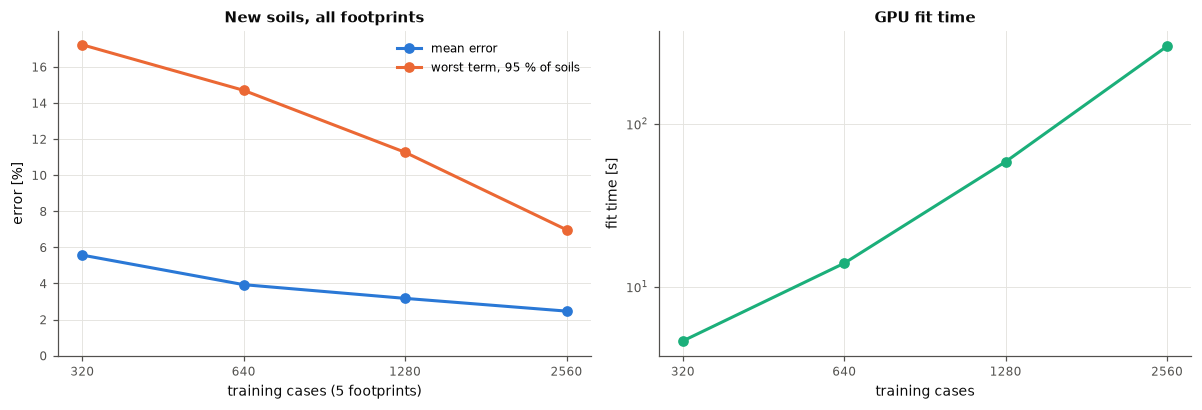

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
n_cases = curve_table["training cases"].values
axes[0].plot(n_cases, curve_table["err_mean"], "o-", color=style.SERIES[0], label="mean error")
axes[0].plot(n_cases, curve_table["err_worst"], "o-", color=style.SERIES[1], label="worst term, 95 % of soils")
axes[0].set(xscale="log", xlabel="training cases (5 footprints)", ylabel="error [%]", ylim=(0, None),
            title="New soils, all footprints")
axes[0].legend()
axes[1].plot(n_cases, curve_table["fit_s"], "o-", color=style.SERIES[2])
axes[1].set(xscale="log", yscale="log", xlabel="training cases", ylabel="fit time [s]", title="GPU fit time")
for ax in axes:
    ax.set_xticks(n_cases, [str(int(v)) for v in n_cases])
    ax.minorticks_off()
fig.tight_layout()

## 3 · A new building, with the fixed recipe

Leave one footprint out, train on the other four with N_LOFO soils each plus their rotated
twins (the left-out footprint's twin is never used), with the linear trend, and predict the
left-out footprint's 32 hold-out soils. Compare with notebook 03, section 6 (128 soils).

In [6]:
lofo = {}
for m in MESHES:
    train = train_pool.take(train_pool.mesh_id != m).head_per_mesh(N_LOFO)
    lofo[m] = fit_and_score(train, test_all.select(mesh=m), rotate=True, trend="all")
    print(f"leave out {m:9s} ({KIND[m]}): fit {lofo[m]['fit_s']:6.1f} s, err_mean {lofo[m]['errors'].mean():.2f} % "
          f"({lofo[m]['report']})")
pd.DataFrame({(m, KIND[m]): row(lofo[m]["errors"]) for m in MESHES}).T.round(2)

leave out m30x15    (extrapolation): fit  159.8 s, err_mean 7.07 % (float32, noise floor 4.1e-04)


leave out m45x15    (interpolation): fit  159.9 s, err_mean 3.98 % (float32, noise floor 4.1e-04)


leave out m60x15    (interpolation): fit  159.9 s, err_mean 5.34 % (float32, noise floor 4.1e-04)


leave out m80x20    (extrapolation): fit  159.9 s, err_mean 8.21 % (float32, noise floor 4.1e-04)


leave out ref33x31  (extrapolation): fit  159.8 s, err_mean 18.80 % (float32, noise floor 4.1e-04)


,,err_mean,err_worst,Ux,Uy,Uz,Rx,Ry,Rz,Ux-Ry,Uy-Rx
m30x15,extrapolation,7.07,14.90,9.26,10.82,7.09,5.39,5.79,8.20,14.90,12.97
m45x15,interpolation,3.98,11.05,8.20,8.85,4.19,4.39,4.86,5.58,11.05,9.42
m60x15,interpolation,5.34,12.50,9.44,9.51,4.99,3.77,3.92,12.50,10.60,10.50
m80x20,extrapolation,8.21,25.73,13.30,12.40,8.95,5.18,14.81,11.65,25.73,13.63
ref33x31,extrapolation,18.80,83.65,15.60,15.44,10.11,11.21,12.74,83.65,23.27,21.16


## 4 · The final model and the experiment table

The model trained on all five footprints with N_FULL soils each, with the trend and the rotated
twins (so that it answers consistently for any orientation), is the one that goes forward to
Milestone 5 (viewer and API). The twins double the cases, so this is the largest fit.

In [7]:
final = fit_and_score(train_pool.head_per_mesh(N_FULL), test_all, rotate=True, trend="all")
print(f"final model: {final['n_train']} training cases, fit {final['fit_s']:.1f} s, "
      f"prediction {final['pred_ms']:.2f} ms per case ({final['report']})")
pd.DataFrame({"all": row(final["errors"]),
              **{m: row(final["errors"][test_all.mesh_id == m]) for m in MESHES}}).T.round(2)

final model: 5120 training cases, fit 1616.2 s, prediction 5.28 ms per case (float32, noise floor 1.0e-03)


,err_mean,err_worst,Ux,Uy,Uz,Rx,Ry,Rz,Ux-Ry,Uy-Rx
all,2.91,8.61,6.34,7.05,3.45,3.16,3.35,4.45,8.61,7.04
m30x15,2.44,5.93,4.34,4.72,4.05,2.11,2.21,2.96,5.93,5.73
m45x15,2.54,6.74,5.27,5.58,2.37,2.43,2.40,2.96,6.74,5.93
m60x15,2.82,7.55,5.35,6.68,3.08,3.35,2.45,3.20,7.55,6.43
m80x20,4.01,12.62,7.58,9.13,3.06,5.30,5.95,5.18,12.62,8.96
ref33x31,2.75,6.82,6.34,6.18,3.06,2.96,2.74,4.04,6.82,6.73


In [8]:
if True:
    band = f"{f[0]:g}-{f[-1]:g}"
    rep = "static (log) + shape, PCA 20"
    model_txt = f"GPU batch GPs (GPyTorch), Matern 5/2 ARD, Adam {N_ITER} steps"
    recipe = model_txt + ", linear trend, rotated twins"
    LOG("M3b-gpu-check256", milestone="M3b", footprints="all 5", validation="hold-out 32 soils per footprint",
                   band_hz=band, n_train=gpu256["n_train"], n_test=gpu256["n_test"], representation=rep,
                   model=model_txt, fit_s=gpu256["fit_s"], predict_ms_per_case=gpu256["pred_ms"],
                   notes="same setup as M3-all-static, on the GPU", **summarize(gpu256["errors"], terms))
    LOG("M3b-gpu-all", milestone="M3b", footprints="all 5", validation="hold-out 32 soils per footprint",
                   band_hz=band, n_train=final["n_train"], n_test=final["n_test"], representation=rep,
                   model=recipe, fit_s=final["fit_s"], predict_ms_per_case=final["pred_ms"],
                   notes=f"{N_FULL} soils per footprint + rotated twins", **summarize(final["errors"], terms))
    pooled = np.vstack([lofo[m]["errors"] for m in MESHES])
    inter = np.vstack([lofo[m]["errors"] for m in MESHES if KIND[m] == "interpolation"])
    for subset, errs in [("all", pooled), ("interp", inter)]:
        LOG(f"M3b-gpu-lofo-{subset}", milestone="M3b",
                       footprints="5 left out in turn" if subset == "all" else "m45x15, m60x15 left out in turn",
                       validation="leave one footprint out, its 32 hold-out soils", band_hz=band,
                       n_train=lofo[MESHES[0]]["n_train"], n_test=len(errs), representation=rep, model=recipe,
                       fit_s=float(np.mean([lofo[m]["fit_s"] for m in MESHES])),
                       notes=f"{N_LOFO} soils per training footprint + rotated twins; errors pooled",
                       **summarize(errs, terms))
read_experiments()[["exp_id", "footprints", "n_train", "err_worst", "err_mean", "fit_s"]].tail(12)

,exp_id,footprints,n_train,err_worst,err_mean,fit_s
8,M3-lofo-pcagp-interp,"m45x15, m60x15 left out in turn",1024.0,280.700,50.620,87.20
9,M3-all-static,all 5,1280.0,10.900,3.207,236.60
10,M3-lofo-static-all,5 left out in turn,1024.0,82.770,16.920,140.90
11,M3-lofo-static-interp,"m45x15, m60x15 left out in turn",1024.0,11.740,5.206,140.90
12,M3-fix-trend-4,"m30x15, m80x20, ref33x31, m45x15 left out in turn",NaN,31.370,11.900,NaN
13,M3-fix-trend-interp,m45x15 left out in turn,NaN,19.050,5.155,NaN
14,M3-fix-trend-rot-4,"m30x15, m80x20, ref33x31, m45x15 left out in turn",NaN,21.990,9.775,NaN
15,M3-fix-trend-rot-interp,m45x15 left out in turn,NaN,13.110,5.336,NaN
16,M3b-gpu-check256,all 5,1280.0,11.030,3.192,60.69
17,M3b-gpu-all,all 5,5120.0,8.615,2.911,1616.00


## 5 · Findings (run of 18 October 2026, RTX 5070 Ti)

- **Same accuracy, 3.9 times faster (section 1).** At 1,280 cases the GPU engine gives a 3.19 %
  mean error and 11.0 % worst term, against 3.21 % and 10.9 % for scikit-learn in notebook 03,
  and fits in 61 s instead of 237 s on the same PC. Adam with a fixed number of steps in single
  precision loses nothing against L-BFGS in double precision here.
- **More soils keep paying (section 2).** With the trend, the mean error falls from 5.6 % at 320
  cases to 3.9 % (640), 3.2 % (1,280) and 2.5 % (2,560), and the worst term from 17.2 % to 7.0 %;
  the fit time grows from 5 s to 5 minutes.
- **Why the final model scores 2.9 % rather than 2.5 %.** It adds the rotated twins. The test
  cases are all in their original orientation, so here the twins (and the larger numerical floor
  that 5,120 cases need) cost a little accuracy; they are kept so that the model also answers for
  rafts turned by 90° (e.g. 15 × 45 m), which the 2,560-case model would have to extrapolate.
- **A new building (section 3).** With trend and rotated twins at 256 soils per footprint, the
  five left-out footprints together give an 8.7 % mean error, half the 16.9 % of the plain
  two-part model with the same soils (notebook 03, row `M3-lofo-static-all`). Between known
  sizes the error stays at 4.7 % (5.2 % without the fixes): the fixes cost nothing where they
  are not needed. One term remains poor: torsion, whose worst case reaches 78 %.
- **The final model (section 4).** 5,120 cases (512 soils × 5 footprints + rotated twins):
  2.9 % mean error, worst term 8.6 % (the Ux–Ry coupling), rocking within 3.4 %, fitted in
  27 minutes. In single precision with the noise floor at 1.0 × 10⁻³ there were no numerical
  fallbacks.
- **Single precision needed a fix.** The first run showed GPyTorch adding jitter, and failing
  at larger sizes: the kernel matrix's largest eigenvalue is close to n, so the fixed noise floor
  of 10⁻⁵ made it too ill-conditioned for float32. The floor now grows with n (note in section 1);
  at 320 and 640 cases the errors did not change.